In [ ]:
# ============================================================
# 0. Install packages
# ============================================================
!pip -q install optuna openpyxl


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 425.6/425.6 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 10.7 MB/s eta 0:00:00


In [ ]:
# ============================================================
# 1. Imports
# ============================================================
import os
import time
import json
import random
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVR, SVC
from sklearn.ensemble import (
    RandomForestRegressor,
    RandomForestClassifier,
    GradientBoostingRegressor,
    GradientBoostingClassifier
)
from sklearn.multioutput import MultiOutputRegressor, MultiOutputClassifier

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import optuna

SEED = 123
np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

RESULTS_DIR = "opfr_net_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

print("TensorFlow:", tf.__version__)
print("Optuna:", optuna.__version__)
print("Results folder:", RESULTS_DIR)


TensorFlow: 2.20.0
Optuna: 4.9.0
Results folder: opfr_net_results


In [ ]:
# ============================================================
# 2. Upload data in Colab
# ============================================================
from google.colab import files

uploaded = files.upload()
DATA_PATH = list(uploaded.keys())[0]

print("Uploaded file:", DATA_PATH)


Saving data_dana_pensiun_9fitur.csv to data_dana_pensiun_9fitur.csv
Uploaded file: data_dana_pensiun_9fitur.csv


In [ ]:
# ============================================================
# 3. Configuration
# ============================================================

FEATURE_COLUMNS = [
    "suku_bunga",
    "inflasi",
    "return_aset",
    "rasio_demografi",
    "funding_ratio_lag1",
    "volatilitas_pasar",
    "liabilitas_aktuaria",
    "iuran_peserta",
    "durasi_obligasi"
]

REG_TARGETS = [
    "funding_ratio",
    "shortfall_3thn"
]

CLS_TARGETS = [
    "risiko_likuiditas",
    "solvency_risk"
]

AUTO_DERIVE_RISK_OUTPUTS = True
SOLVENCY_QUANTILE = 0.25
LIQUIDITY_QUANTILE = 0.25

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

N_TRIALS = 15
EPOCHS_TUNING = 80
EPOCHS_FINAL = 200
PATIENCE = 20


In [ ]:
# ============================================================
# 4. Utility functions
# ============================================================

def save_table(df, filename_base):
    csv_path = os.path.join(RESULTS_DIR, filename_base + ".csv")
    tex_path = os.path.join(RESULTS_DIR, filename_base + ".tex")
    df.to_csv(csv_path, index=False)
    with open(tex_path, "w") as f:
        f.write(df.to_latex(index=False, escape=False))
    print("Saved:", csv_path)
    print("Saved:", tex_path)


def chronological_split(df, train_ratio=0.70, val_ratio=0.15):
    n = len(df)
    train_end = int(n * train_ratio)
    val_end = int(n * (train_ratio + val_ratio))
    return df.iloc[:train_end].copy(), df.iloc[train_end:val_end].copy(), df.iloc[val_end:].copy()


def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), 1e-8))) * 100
    r2 = r2_score(y_true, y_pred, multioutput="uniform_average")
    return {"MAE": mae, "RMSE": rmse, "MAPE": mape, "R2": r2}


def classification_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "F1-score": f1_score(y_true, y_pred, average="macro", zero_division=0)
    }


def check_target_variation(df, columns):
    out = []
    for col in columns:
        out.append({
            "Target": col,
            "Unique values": df[col].nunique(),
            "Minimum": df[col].min(),
            "Maximum": df[col].max(),
            "Sum": df[col].sum()
        })
    return pd.DataFrame(out)


def derive_risk_outputs(df):
    out = df.copy()

    solvency_threshold = out["funding_ratio"].quantile(SOLVENCY_QUANTILE)
    out["solvency_risk"] = (out["funding_ratio"] <= solvency_threshold).astype(int)

    out["shortfall_3thn"] = np.maximum(0, solvency_threshold - out["funding_ratio"])

    liquidity_ratio = out["iuran_peserta"] / np.maximum(out["liabilitas_aktuaria"], 1e-8)
    liquidity_threshold = liquidity_ratio.quantile(LIQUIDITY_QUANTILE)
    out["risiko_likuiditas"] = (liquidity_ratio <= liquidity_threshold).astype(int)

    print("Derived solvency threshold:", solvency_threshold)
    print("Derived liquidity threshold:", liquidity_threshold)

    return out


In [ ]:
# ============================================================
# 5. Load and inspect data
# ============================================================

df = pd.read_csv(DATA_PATH)

print("Data shape:", df.shape)
print("Columns:", list(df.columns))
display(df.head())

required = FEATURE_COLUMNS + REG_TARGETS + CLS_TARGETS
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError("Missing required columns: " + str(missing))

for col in required:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=required).reset_index(drop=True)

target_diag_before = check_target_variation(df, REG_TARGETS + CLS_TARGETS)
print("Target diagnostics before adjustment:")
display(target_diag_before)

constant_targets = [c for c in ["shortfall_3thn", "risiko_likuiditas", "solvency_risk"] if df[c].nunique() <= 1]
if AUTO_DERIVE_RISK_OUTPUTS and len(constant_targets) > 0:
    print("Constant target columns detected:", constant_targets)
    print("Constructing derived early-warning risk outputs.")
    df = derive_risk_outputs(df)

target_diag_after = check_target_variation(df, REG_TARGETS + CLS_TARGETS)
print("Target diagnostics after adjustment:")
display(target_diag_after)

desc = df[FEATURE_COLUMNS + REG_TARGETS].describe().T
desc = desc[["mean", "std", "min", "max"]].reset_index()
desc.columns = ["Variable", "Mean", "Standard deviation", "Minimum", "Maximum"]
desc = desc.round(4)

save_table(desc, "table_descriptive_statistics")
display(desc)


Data shape: (75, 14)
Columns: ['Periode', 'suku_bunga', 'inflasi', 'return_aset', 'rasio_demografi', 'funding_ratio_lag1', 'volatilitas_pasar', 'liabilitas_aktuaria', 'iuran_peserta', 'durasi_obligasi', 'funding_ratio', 'risiko_likuiditas', 'shortfall_3thn', 'solvency_risk']


,Periode,suku_bunga,inflasi,return_aset,rasio_demografi,funding_ratio_lag1,volatilitas_pasar,liabilitas_aktuaria,iuran_peserta,durasi_obligasi,funding_ratio,risiko_likuiditas,shortfall_3thn,solvency_risk
0,Januari 2020,5.00,2.68,0.5604,3.52,15254.13,3.7961,2.047176,366.1565,7.71,14229.87,0,0.0,0
1,Februari 2020,4.75,2.98,1.1689,3.41,14229.87,3.7576,2.632756,353.6391,7.39,10992.54,0,0.0,0
2,Maret 2020,4.50,2.96,1.5596,3.54,10992.54,0.5035,2.620614,366.8566,7.57,10673.83,0,0.0,0
3,April 2020,4.50,2.67,2.0552,3.55,10673.83,0.4442,2.624085,401.3978,7.73,10776.63,0,0.0,0
4,Mei 2020,4.50,2.19,2.5560,3.31,10776.63,0.4982,1.954536,393.7737,7.46,14557.28,0,0.0,0


Target diagnostics before adjustment:


,Target,Unique values,Minimum,Maximum,Sum
0,funding_ratio,75,10673.83,20334.4,1133691.03
1,shortfall_3thn,1,0.00,0.0,0.00
2,risiko_likuiditas,1,0.00,0.0,0.00
3,solvency_risk,1,0.00,0.0,0.00


Constant target columns detected: ['shortfall_3thn', 'risiko_likuiditas', 'solvency_risk']
Constructing derived early-warning risk outputs.
Derived solvency threshold: 14134.735
Derived liquidity threshold: 69.47750591229178
Target diagnostics after adjustment:


,Target,Unique values,Minimum,Maximum,Sum
0,funding_ratio,75,10673.83,20334.400,1133691.030
1,shortfall_3thn,20,0.00,3460.905,27192.705
2,risiko_likuiditas,2,0.00,1.000,19.000
3,solvency_risk,2,0.00,1.000,19.000


Saved: opfr_net_results/table_descriptive_statistics.csv
Saved: opfr_net_results/table_descriptive_statistics.tex


,Variable,Mean,Standard deviation,Minimum,Maximum
0,suku_bunga,4.8000,1.0495,2.7500,6.2500
1,inflasi,2.6697,1.3117,-0.0900,5.9500
2,return_aset,3.3914,1.8779,0.4719,6.5176
3,rasio_demografi,3.1517,0.2178,2.7400,3.5500
4,funding_ratio_lag1,15109.1435,1877.9603,10673.8300,20334.4000
5,volatilitas_pasar,1.0353,1.0793,0.3658,3.7961
6,liabilitas_aktuaria,2.3151,0.2754,1.5858,2.9521
7,iuran_peserta,231.4103,80.8017,137.8796,489.3143
8,durasi_obligasi,7.9644,0.4170,7.2500,9.2400
9,funding_ratio,15115.8804,1879.3932,10673.8300,20334.4000


In [ ]:
# ============================================================
# 6. Chronological train-validation-test split and scaling
# ============================================================

train_df, val_df, test_df = chronological_split(df, TRAIN_RATIO, VAL_RATIO)

X_train_raw = train_df[FEATURE_COLUMNS].values
X_val_raw = val_df[FEATURE_COLUMNS].values
X_test_raw = test_df[FEATURE_COLUMNS].values

y_train_reg_raw = train_df[REG_TARGETS].values
y_val_reg_raw = val_df[REG_TARGETS].values
y_test_reg_raw = test_df[REG_TARGETS].values

y_train_cls = train_df[CLS_TARGETS].values.astype(int)
y_val_cls = val_df[CLS_TARGETS].values.astype(int)
y_test_cls = test_df[CLS_TARGETS].values.astype(int)

x_scaler = StandardScaler()
y_reg_scaler = StandardScaler()

X_train = x_scaler.fit_transform(X_train_raw)
X_val = x_scaler.transform(X_val_raw)
X_test = x_scaler.transform(X_test_raw)

y_train_reg = y_reg_scaler.fit_transform(y_train_reg_raw)
y_val_reg = y_reg_scaler.transform(y_val_reg_raw)
y_test_reg = y_reg_scaler.transform(y_test_reg_raw)

split_table = pd.DataFrame({
    "Subset": ["Training set", "Validation set", "Testing set"],
    "Number of observations": [len(train_df), len(val_df), len(test_df)],
    "Proportion": [len(train_df)/len(df), len(val_df)/len(df), len(test_df)/len(df)]
})
split_table["Proportion"] = split_table["Proportion"].round(4)

save_table(split_table, "table_data_split")
display(split_table)

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)


Saved: opfr_net_results/table_data_split.csv
Saved: opfr_net_results/table_data_split.tex


,Subset,Number of observations,Proportion
0,Training set,52,0.6933
1,Validation set,11,0.1467
2,Testing set,12,0.1600


Train: (52, 9) Validation: (11, 9) Test: (12, 9)


In [ ]:
# ============================================================
# 7. OPFR-Net model functions
# ============================================================

def build_opfr_net(input_dim, params):
    n_layers = params.get("n_layers", 3)
    activation = params.get("activation", "relu")
    dropout_rate = params.get("dropout_rate", 0.25)
    learning_rate = params.get("learning_rate", 1e-3)
    alpha = params.get("alpha", 0.70)

    inputs = keras.Input(shape=(input_dim,), name="input_layer")
    x = inputs

    for i in range(n_layers):
        units = params.get(f"n_units_l{i+1}", 64)
        x = layers.Dense(units, activation=activation, name=f"dense_{i+1}")(x)
        x = layers.BatchNormalization(name=f"batch_norm_{i+1}")(x)
        x = layers.Dropout(dropout_rate, name=f"dropout_{i+1}")(x)

    reg_output = layers.Dense(len(REG_TARGETS), activation="linear", name="reg_output")(x)
    cls_output = layers.Dense(len(CLS_TARGETS), activation="sigmoid", name="cls_output")(x)

    model = keras.Model(inputs=inputs, outputs=[reg_output, cls_output], name="OPFR_Net")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss={"reg_output": "mse", "cls_output": "binary_crossentropy"},
        loss_weights={"reg_output": alpha, "cls_output": 1-alpha},
        metrics={
            "reg_output": [keras.metrics.RootMeanSquaredError(name="rmse")],
            "cls_output": [keras.metrics.BinaryAccuracy(name="binary_accuracy")]
        }
    )

    return model


def train_opfr_model(model, epochs, batch_size):
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        {"reg_output": y_train_reg, "cls_output": y_train_cls},
        validation_data=(X_val, {"reg_output": y_val_reg, "cls_output": y_val_cls}),
        epochs=epochs,
        batch_size=batch_size,
        verbose=0,
        callbacks=[early_stop]
    )
    return history


def predict_opfr(model, X):
    pred_reg_scaled, pred_cls_prob = model.predict(X, verbose=0)
    pred_reg = y_reg_scaler.inverse_transform(pred_reg_scaled)
    return pred_reg, pred_cls_prob


In [ ]:
# ============================================================
# 8. Standard DNN benchmark
# ============================================================

standard_params = {
    "n_layers": 3,
    "n_units_l1": 128,
    "n_units_l2": 64,
    "n_units_l3": 32,
    "activation": "relu",
    "dropout_rate": 0.25,
    "learning_rate": 1e-3,
    "alpha": 0.70
}

tf.keras.backend.clear_session()
start_time = time.time()

standard_dnn = build_opfr_net(X_train.shape[1], standard_params)
history_standard = train_opfr_model(standard_dnn, EPOCHS_FINAL, batch_size=16)

standard_training_time = time.time() - start_time
standard_params_count = standard_dnn.count_params()

std_pred_reg, std_pred_cls_prob = predict_opfr(standard_dnn, X_test)

print("Standard DNN training time:", round(standard_training_time, 4))
print("Standard DNN trainable parameters:", standard_params_count)


Standard DNN training time: 9.6995
Standard DNN trainable parameters: 12644


In [ ]:
# ============================================================
# 9. Hyperparameter optimization with Optuna
# ============================================================

def objective(trial):
    tf.keras.backend.clear_session()

    n_layers = trial.suggest_int("n_layers", 2, 5)
    params = {
        "n_layers": n_layers,
        "activation": trial.suggest_categorical("activation", ["relu", "elu", "gelu"]),
        "dropout_rate": trial.suggest_float("dropout_rate", 0.10, 0.50),
        "learning_rate": trial.suggest_float("learning_rate", 1e-4, 1e-2, log=True),
        "alpha": trial.suggest_float("alpha", 0.50, 0.85)
    }

    for i in range(n_layers):
        params[f"n_units_l{i+1}"] = trial.suggest_int(f"n_units_l{i+1}", 16, 256, step=16)

    batch_size = trial.suggest_categorical("batch_size", [8, 16, 32, 64])

    model = build_opfr_net(X_train.shape[1], params)

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )

    history = model.fit(
        X_train,
        {"reg_output": y_train_reg, "cls_output": y_train_cls},
        validation_data=(X_val, {"reg_output": y_val_reg, "cls_output": y_val_cls}),
        epochs=EPOCHS_TUNING,
        batch_size=batch_size,
        verbose=0,
        callbacks=[early_stop]
    )

    best_val_loss = float(np.min(history.history["val_loss"]))
    complexity_penalty = 1e-7 * model.count_params()
    return best_val_loss + complexity_penalty


optuna.logging.set_verbosity(optuna.logging.WARNING)

study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED)
)
study.optimize(objective, n_trials=N_TRIALS)

best_params = study.best_params.copy()

print("Best validation objective:", study.best_value)
print(json.dumps(best_params, indent=2))

hyper_table = pd.DataFrame({
    "Hyperparameter": list(best_params.keys()),
    "Selected value": list(best_params.values())
})

save_table(hyper_table, "table_optimized_hyperparameters")
display(hyper_table)


Best validation objective: 0.13866429434223176
{
  "n_layers": 3,
  "activation": "gelu",
  "dropout_rate": 0.18900562350010144,
  "learning_rate": 0.003946693124061003,
  "alpha": 0.8181696375829576,
  "n_units_l1": 256,
  "n_units_l2": 80,
  "n_units_l3": 16,
  "batch_size": 32
}
Saved: opfr_net_results/table_optimized_hyperparameters.csv
Saved: opfr_net_results/table_optimized_hyperparameters.tex


,Hyperparameter,Selected value
0,n_layers,3
1,activation,gelu
2,dropout_rate,0.189006
3,learning_rate,0.003947
4,alpha,0.81817
5,n_units_l1,256
6,n_units_l2,80
7,n_units_l3,16
8,batch_size,32


In [ ]:
# ============================================================
# 10. Train optimized OPFR-Net
# ============================================================

opfr_params = best_params.copy()
batch_size_best = int(opfr_params.pop("batch_size"))

tf.keras.backend.clear_session()
start_time = time.time()

opfr_net = build_opfr_net(X_train.shape[1], opfr_params)
history_opfr = train_opfr_model(opfr_net, EPOCHS_FINAL, batch_size=batch_size_best)

opfr_training_time = time.time() - start_time
opfr_params_count = opfr_net.count_params()

opfr_pred_reg, opfr_pred_cls_prob = predict_opfr(opfr_net, X_test)

print("OPFR-Net training time:", round(opfr_training_time, 4))
print("OPFR-Net trainable parameters:", opfr_params_count)


OPFR-Net training time: 16.9581
OPFR-Net trainable parameters: 25892


In [ ]:
# ============================================================
# 11. Benchmark comparisons
# ============================================================

regression_results = []
classification_results = []

regressors = {
    "Linear regression": LinearRegression(),
    "Support vector regression": MultiOutputRegressor(SVR(kernel="rbf")),
    "Random forest": RandomForestRegressor(n_estimators=300, random_state=SEED),
    "Gradient boosting": MultiOutputRegressor(GradientBoostingRegressor(random_state=SEED))
}

for name, model in regressors.items():
    model.fit(X_train, y_train_reg_raw)
    pred = model.predict(X_test)
    metrics = regression_metrics(y_test_reg_raw, pred)
    metrics["Model"] = name
    regression_results.append(metrics)

m = regression_metrics(y_test_reg_raw, std_pred_reg)
m["Model"] = "Standard DNN"
regression_results.append(m)

m = regression_metrics(y_test_reg_raw, opfr_pred_reg)
m["Model"] = "OPFR-Net"
regression_results.append(m)

reg_df = pd.DataFrame(regression_results)
reg_df = reg_df[["Model", "MAE", "RMSE", "MAPE", "R2"]]
reg_df[["MAE", "RMSE", "MAPE", "R2"]] = reg_df[["MAE", "RMSE", "MAPE", "R2"]].round(4)

save_table(reg_df, "table_regression_results")
display(reg_df)

classifiers = {
    "Logistic regression": MultiOutputClassifier(LogisticRegression(max_iter=2000, random_state=SEED)),
    "Support vector machine": MultiOutputClassifier(SVC(kernel="rbf", probability=True, random_state=SEED)),
    "Random forest": MultiOutputClassifier(RandomForestClassifier(n_estimators=300, random_state=SEED)),
    "Gradient boosting": MultiOutputClassifier(GradientBoostingClassifier(random_state=SEED))
}

for name, model in classifiers.items():
    try:
        model.fit(X_train, y_train_cls)
        prob_list = model.predict_proba(X_test)
        prob = np.column_stack([p[:, 1] if p.shape[1] > 1 else np.zeros(len(X_test)) for p in prob_list])
        metrics = classification_metrics(y_test_cls, prob)
        metrics["Model"] = name
        classification_results.append(metrics)
    except Exception as e:
        classification_results.append({
            "Model": name,
            "Accuracy": np.nan,
            "Precision": np.nan,
            "Recall": np.nan,
            "F1-score": np.nan
        })
        print(name, "skipped:", e)

m = classification_metrics(y_test_cls, std_pred_cls_prob)
m["Model"] = "Standard DNN"
classification_results.append(m)

m = classification_metrics(y_test_cls, opfr_pred_cls_prob)
m["Model"] = "OPFR-Net"
classification_results.append(m)

cls_df = pd.DataFrame(classification_results)
cls_df = cls_df[["Model", "Accuracy", "Precision", "Recall", "F1-score"]]
cls_df[["Accuracy", "Precision", "Recall", "F1-score"]] = cls_df[["Accuracy", "Precision", "Recall", "F1-score"]].round(4)

save_table(cls_df, "table_classification_results")
display(cls_df)


Saved: opfr_net_results/table_regression_results.csv
Saved: opfr_net_results/table_regression_results.tex


,Model,MAE,RMSE,MAPE,R2
0,Linear regression,484.1164,540.7858,1.825514e+12,-0.3050
1,Support vector regression,696.1795,1039.0656,3.811486e+09,-0.5985
2,Random forest,1046.1865,1254.4926,2.393659e+12,-2.4683
3,Gradient boosting,963.9692,1140.6263,2.724302e+12,-3.6879
4,Standard DNN,619.7274,761.5216,2.284019e+12,-0.9391
5,OPFR-Net,425.1570,640.3753,2.027221e+11,0.1307


Saved: opfr_net_results/table_classification_results.csv
Saved: opfr_net_results/table_classification_results.tex


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic regression,0.8333,1.0000,0.9091,0.9500
1,Support vector machine,0.0833,0.0000,0.0000,0.0000
2,Random forest,0.1667,0.5833,0.6364,0.3571
3,Gradient boosting,0.5000,0.5833,0.9091,0.5929
4,Standard DNN,0.0833,0.5000,1.0000,0.5552
5,OPFR-Net,0.0833,0.5000,0.0455,0.0833


In [ ]:
# ============================================================
# 12. Ablation study
# ============================================================

def train_eval_for_ablation(params, feature_subset):
    Xtr_raw = train_df[feature_subset].values
    Xva_raw = val_df[feature_subset].values
    Xte_raw = test_df[feature_subset].values

    scaler = StandardScaler()
    Xtr = scaler.fit_transform(Xtr_raw)
    Xva = scaler.transform(Xva_raw)
    Xte = scaler.transform(Xte_raw)

    tf.keras.backend.clear_session()
    model = build_opfr_net(len(feature_subset), params)

    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    model.fit(
        Xtr,
        {"reg_output": y_train_reg, "cls_output": y_train_cls},
        validation_data=(Xva, {"reg_output": y_val_reg, "cls_output": y_val_cls}),
        epochs=EPOCHS_FINAL,
        batch_size=params.get("batch_size", 16),
        verbose=0,
        callbacks=[early_stop]
    )

    pred_reg_scaled, pred_cls_prob = model.predict(Xte, verbose=0)
    pred_reg = y_reg_scaler.inverse_transform(pred_reg_scaled)
    rmse = np.sqrt(mean_squared_error(y_test_reg_raw, pred_reg))
    return rmse


rf_selector = RandomForestRegressor(n_estimators=300, random_state=SEED)
rf_selector.fit(X_train_raw, y_train_reg_raw[:, 0])

feature_importance_rf = pd.Series(
    rf_selector.feature_importances_,
    index=FEATURE_COLUMNS
).sort_values(ascending=False)

TOP_K = min(6, len(FEATURE_COLUMNS))
selected_features = feature_importance_rf.head(TOP_K).index.tolist()

print("Selected features:", selected_features)

standard_ablation_params = standard_params.copy()
standard_ablation_params["batch_size"] = 16

opfr_ablation_params = opfr_params.copy()
opfr_ablation_params["batch_size"] = batch_size_best

rmse_standard = train_eval_for_ablation(standard_ablation_params, FEATURE_COLUMNS)
rmse_feature = train_eval_for_ablation(standard_ablation_params, selected_features)
rmse_hyper = train_eval_for_ablation(opfr_ablation_params, FEATURE_COLUMNS)
rmse_opfr = train_eval_for_ablation(opfr_ablation_params, selected_features)

ablation_df = pd.DataFrame({
    "Model configuration": [
        "Standard DNN",
        "DNN + feature optimization",
        "DNN + hyperparameter optimization",
        "OPFR-Net"
    ],
    "Feature optimization": ["No", "Yes", "No", "Yes"],
    "Hyperparameter optimization": ["No", "No", "Yes", "Yes"],
    "RMSE": [rmse_standard, rmse_feature, rmse_hyper, rmse_opfr]
})
ablation_df["RMSE"] = ablation_df["RMSE"].round(4)

save_table(ablation_df, "table_ablation_results")
display(ablation_df)


Selected features: ['liabilitas_aktuaria', 'iuran_peserta', 'rasio_demografi', 'funding_ratio_lag1', 'inflasi', 'durasi_obligasi']


Saved: opfr_net_results/table_ablation_results.csv
Saved: opfr_net_results/table_ablation_results.tex


,Model configuration,Feature optimization,Hyperparameter optimization,RMSE
0,Standard DNN,No,No,733.1949
1,DNN + feature optimization,Yes,No,601.8990
2,DNN + hyperparameter optimization,No,Yes,554.2213
3,OPFR-Net,Yes,Yes,669.4977


Saved: opfr_net_results/table_training_validation_loss.csv
Saved: opfr_net_results/table_training_validation_loss.tex


,Epoch,Training loss,Validation loss
0,1,2.358647,0.390288
1,2,1.215676,0.361342
2,3,0.774941,0.340671
3,4,0.623996,0.324973
4,5,0.783096,0.316906


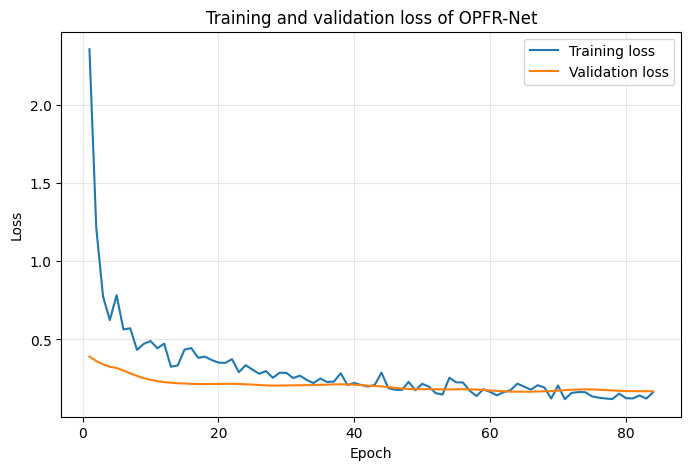

In [ ]:
# ============================================================
# 13. Training-validation loss
# ============================================================

loss_df = pd.DataFrame({
    "Epoch": np.arange(1, len(history_opfr.history["loss"]) + 1),
    "Training loss": history_opfr.history["loss"],
    "Validation loss": history_opfr.history["val_loss"]
})

loss_df[["Training loss", "Validation loss"]] = loss_df[["Training loss", "Validation loss"]].round(6)
save_table(loss_df, "table_training_validation_loss")
display(loss_df.head())

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(loss_df["Epoch"], loss_df["Training loss"], label="Training loss")
plt.plot(loss_df["Epoch"], loss_df["Validation loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and validation loss of OPFR-Net")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(RESULTS_DIR, "figure_training_validation_loss.png"), dpi=300, bbox_inches="tight")
plt.show()


Saved: opfr_net_results/table_prediction_residuals.csv
Saved: opfr_net_results/table_prediction_residuals.tex


,Actual funding ratio,Predicted funding ratio,Residual
0,13060.46,14558.135742,-1497.6757
1,15922.59,15520.054688,402.5363
2,16852.89,15509.633789,1343.2572
3,15801.79,15243.260742,558.5293
4,15659.18,15075.694336,583.4857
5,14837.96,14996.985352,-159.0254
6,16890.34,15544.385742,1345.9543
7,16726.49,15551.123047,1175.3670
8,15527.64,15228.998047,298.6420
9,15607.34,15082.971680,524.3693


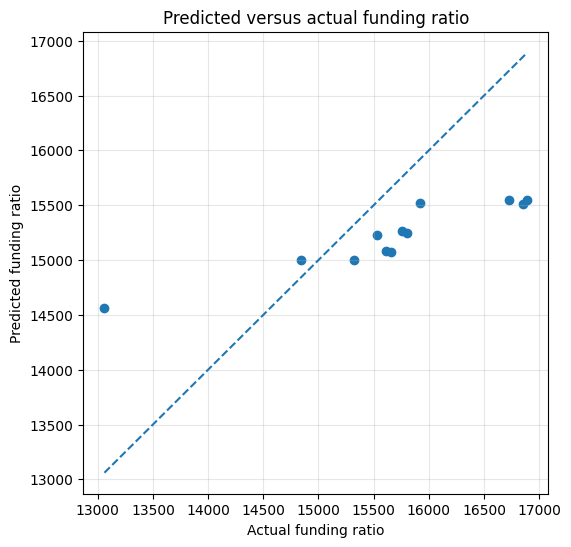

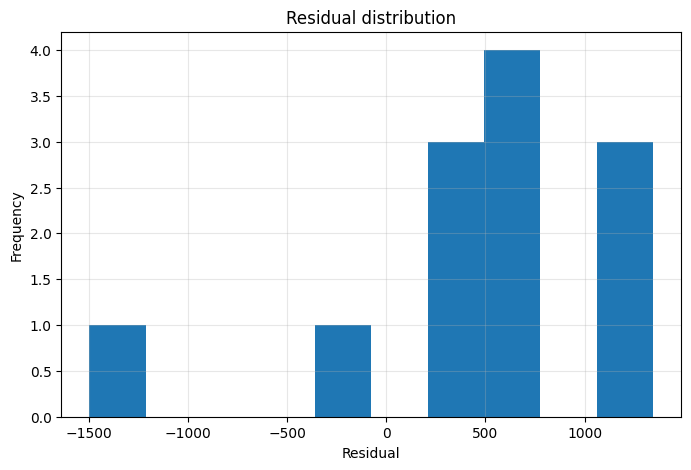

In [ ]:
# ============================================================
# 14. Prediction diagnostics
# ============================================================

pred_df = pd.DataFrame({
    "Actual funding ratio": y_test_reg_raw[:, 0],
    "Predicted funding ratio": opfr_pred_reg[:, 0],
    "Residual": y_test_reg_raw[:, 0] - opfr_pred_reg[:, 0]
})
pred_df = pred_df.round(4)

save_table(pred_df, "table_prediction_residuals")
display(pred_df)

plt.figure(figsize=(6, 6))
plt.scatter(pred_df["Actual funding ratio"], pred_df["Predicted funding ratio"])
min_val = min(pred_df["Actual funding ratio"].min(), pred_df["Predicted funding ratio"].min())
max_val = max(pred_df["Actual funding ratio"].max(), pred_df["Predicted funding ratio"].max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.xlabel("Actual funding ratio")
plt.ylabel("Predicted funding ratio")
plt.title("Predicted versus actual funding ratio")
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(RESULTS_DIR, "figure_predicted_vs_actual.png"), dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(pred_df["Residual"], bins=10)
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Residual distribution")
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(RESULTS_DIR, "figure_residual_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()


Saved: opfr_net_results/table_feature_importance.csv
Saved: opfr_net_results/table_feature_importance.tex


,Rank,Variable,Importance value
0,1,liabilitas_aktuaria,173.671632
1,2,rasio_demografi,17.989203
2,3,return_aset,1.652884
3,4,inflasi,-0.504476
4,5,iuran_peserta,-3.835901
5,6,funding_ratio_lag1,-4.101977
6,7,suku_bunga,-6.443638
7,8,durasi_obligasi,-6.925548
8,9,volatilitas_pasar,-7.361309


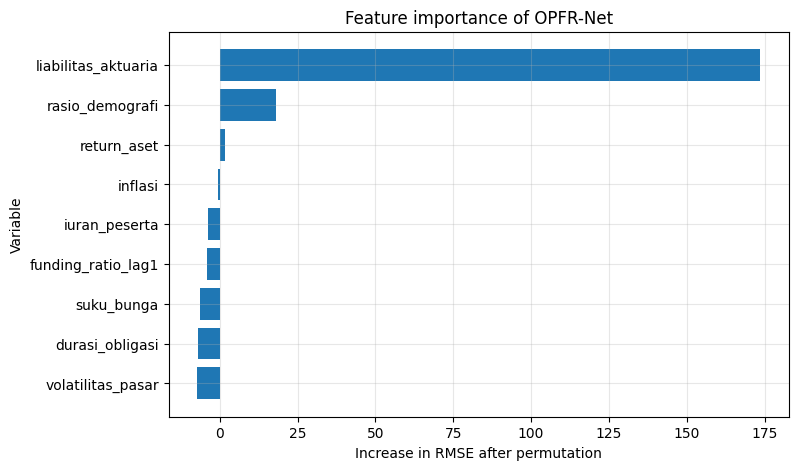

In [ ]:
# ============================================================
# 15. Feature importance using permutation method
# ============================================================

def predict_funding_ratio_from_raw(X_raw):
    X_scaled = x_scaler.transform(X_raw)
    pred_reg, _ = predict_opfr(opfr_net, X_scaled)
    return pred_reg[:, 0]

baseline_pred = predict_funding_ratio_from_raw(X_test_raw)
baseline_rmse = np.sqrt(mean_squared_error(y_test_reg_raw[:, 0], baseline_pred))

rng = np.random.default_rng(SEED)
importance_rows = []

for j, feature in enumerate(FEATURE_COLUMNS):
    X_perm = X_test_raw.copy()
    X_perm[:, j] = rng.permutation(X_perm[:, j])
    pred_perm = predict_funding_ratio_from_raw(X_perm)
    perm_rmse = np.sqrt(mean_squared_error(y_test_reg_raw[:, 0], pred_perm))
    importance_rows.append({
        "Variable": feature,
        "Importance value": perm_rmse - baseline_rmse
    })

importance_df = pd.DataFrame(importance_rows)
importance_df = importance_df.sort_values("Importance value", ascending=False).reset_index(drop=True)
importance_df.insert(0, "Rank", np.arange(1, len(importance_df) + 1))
importance_df["Importance value"] = importance_df["Importance value"].round(6)

save_table(importance_df, "table_feature_importance")
display(importance_df)

plt.figure(figsize=(8, 5))
plt.barh(importance_df["Variable"][::-1], importance_df["Importance value"][::-1])
plt.xlabel("Increase in RMSE after permutation")
plt.ylabel("Variable")
plt.title("Feature importance of OPFR-Net")
plt.grid(True, alpha=0.3)
plt.savefig(os.path.join(RESULTS_DIR, "figure_feature_importance.png"), dpi=300, bbox_inches="tight")
plt.show()


In [ ]:
# ============================================================
# 16. Sensitivity analysis
# ============================================================

def predict_mean_funding_ratio(X_raw):
    return float(np.mean(predict_funding_ratio_from_raw(X_raw)))

baseline_mean_fr = predict_mean_funding_ratio(X_test_raw)

scenarios = [
    ("Interest rate increase", "suku_bunga", 0.10),
    ("Inflation increase", "inflasi", 0.10),
    ("Investment return decrease", "return_aset", -0.10),
    ("Market volatility increase", "volatilitas_pasar", 0.10),
    ("Actuarial liability increase", "liabilitas_aktuaria", 0.10),
    ("Contribution decrease", "iuran_peserta", -0.10)
]

sensitivity_rows = []

for scenario, feature, delta in scenarios:
    X_scenario = X_test_raw.copy()
    j = FEATURE_COLUMNS.index(feature)
    X_scenario[:, j] = X_scenario[:, j] * (1 + delta)

    scenario_mean_fr = predict_mean_funding_ratio(X_scenario)
    change = scenario_mean_fr - baseline_mean_fr

    if change < 0:
        interpretation = "Increases pension fund risk"
    elif change > 0:
        interpretation = "Reduces pension fund risk"
    else:
        interpretation = "No material change"

    sensitivity_rows.append({
        "Scenario": scenario,
        "Change": f"{delta*100:.0f}%",
        "Predicted funding ratio change": change,
        "Risk interpretation": interpretation
    })

sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_df["Predicted funding ratio change"] = sensitivity_df["Predicted funding ratio change"].round(4)

save_table(sensitivity_df, "table_sensitivity_analysis")
display(sensitivity_df)


Saved: opfr_net_results/table_sensitivity_analysis.csv
Saved: opfr_net_results/table_sensitivity_analysis.tex


,Scenario,Change,Predicted funding ratio change,Risk interpretation
0,Interest rate increase,10%,35.7168,Reduces pension fund risk
1,Inflation increase,10%,15.0693,Reduces pension fund risk
2,Investment return decrease,-10%,-5.1182,Increases pension fund risk
3,Market volatility increase,10%,-3.1465,Increases pension fund risk
4,Actuarial liability increase,10%,-423.3525,Increases pension fund risk
5,Contribution decrease,-10%,10.3779,Reduces pension fund risk


In [ ]:
# ============================================================
# 17. Computational performance
# ============================================================

comp_df = pd.DataFrame({
    "Model": ["Standard DNN", "OPFR-Net"],
    "Training time": [
        f"{standard_training_time:.4f} seconds",
        f"{opfr_training_time:.4f} seconds"
    ],
    "Number of trainable parameters": [
        standard_params_count,
        opfr_params_count
    ]
})

save_table(comp_df, "table_computational_performance")
display(comp_df)


Saved: opfr_net_results/table_computational_performance.csv
Saved: opfr_net_results/table_computational_performance.tex


,Model,Training time,Number of trainable parameters
0,Standard DNN,9.6995 seconds,12644
1,OPFR-Net,16.9581 seconds,25892


In [ ]:
# ============================================================
# 18. Export all results as ZIP
# ============================================================

import shutil

zip_base = "opfr_net_results"
zip_path = zip_base + ".zip"

if os.path.exists(zip_path):
    os.remove(zip_path)

shutil.make_archive(zip_base, "zip", RESULTS_DIR)

print("ZIP created:", zip_path)

from google.colab import files
files.download(zip_path)


ZIP created: opfr_net_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>